In [1]:
# Local environment: run with the existing ai Python environment.
# Dependencies: torch, torchvision, numpy, matplotlib. No installation is needed.


In [2]:
from pathlib import Path
import os

# Accept a kernel started either in assignment2 or in its parent directory.
assignment_dir = Path.cwd()
if not (assignment_dir / 'cs682' / 'datasets').is_dir():
    assignment_dir = assignment_dir / 'assignment2'
if not (assignment_dir / 'cs682' / 'datasets' / 'cifar-10-batches-py').is_dir():
    raise FileNotFoundError('Start this notebook in assignment2 with the local CIFAR-10 data present.')
os.chdir(assignment_dir)
print('Assignment directory:', assignment_dir)


Assignment directory: /Users/while/Desktop/cs/682/assignment2


# What's this PyTorch business?

You've written a lot of code in this assignment to provide a whole host of neural network functionality. Dropout, Batch Norm, and 2D convolutions are some of the workhorses of deep learning in computer vision. You've also worked hard to make your code efficient and vectorized.

For the last part of this assignment, though, we're going to leave behind your beautiful codebase and instead migrate to one of two popular deep learning frameworks: in this instance, PyTorch. 

### What is PyTorch?

PyTorch is a system for executing dynamic computational graphs over Tensor objects that behave similarly as numpy ndarray. It comes with a powerful automatic differentiation engine that removes the need for manual back-propagation. 

### Why do we use deep learning frameworks?

* Our code will now run on GPUs! Much faster training. When using a framework like PyTorch you can harness the power of the GPU for your own custom neural network architectures without having to write CUDA code directly (which is beyond the scope of this class).
* We want you to be ready to use one of these frameworks for your project so you can experiment more efficiently than if you were writing every feature you want to use by hand.
* We want you to stand on the shoulders of giants! PyTorch is an excellent framework that will make your lives a lot easier, and now that you understand their guts, you are free to use them :)
* We want you to be exposed to the sort of deep learning code you might run into in academia or industry.

## How will I learn PyTorch?

Justin Johnson has made an excellent [tutorial](https://github.com/jcjohnson/pytorch-examples) for PyTorch. 

You can also find the detailed [API doc](http://pytorch.org/docs/stable/index.html) here. If you have other questions that are not addressed by the API docs, the [PyTorch forum](https://discuss.pytorch.org/) is a much better place to ask than StackOverflow.

# Table of Contents

This assignment has 5 parts. You will learn PyTorch on different levels of abstractions, which will help you understand it better and prepare you for the final project. 

1. Preparation: we will use CIFAR-10 dataset.
2. Barebones PyTorch: we will work directly with the lowest-level PyTorch Tensors. 
3. PyTorch Module API: we will use `nn.Module` to define arbitrary neural network architecture. 
4. PyTorch Sequential API: we will use `nn.Sequential` to define a linear feed-forward network very conveniently. 
5. CIFAR-10 open-ended challenge: please implement your own network to get as high accuracy as possible on CIFAR-10. You can experiment with any layer, optimizer, hyperparameters or other advanced features. 

Here is a table of comparison:

| API           | Flexibility | Convenience |
|---------------|-------------|-------------|
| Barebone      | High        | Low         |
| `nn.Module`     | High        | Medium      |
| `nn.Sequential` | Low         | High        |

# GPU

You can manually switch to a GPU device on Colab by clicking `Runtime -> Change runtime type` and selecting `GPU` under `Hardware Accelerator`. You should do this before running the following cells to import packages, since the kernel gets restarted upon switching runtimes.

Alternatively, if you have a GPU on your computer, you can choose to install PyTorch by following the instructions [here](https://pytorch.org/get-started/locally/).

In [3]:
import copy
import json
import random
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import sampler

import torchvision.datasets as dset
import torchvision.transforms as T

import numpy as np
import matplotlib.pyplot as plt



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/while/.cache/fontconfig
	/Users/while/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/while/.cache/fontconfig
	/Users/while/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/while/.cache/fontconfig
	/Users/while/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/while/.cache/fontconfig
	/Users/while/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/while/.cache/fontconfig
	/Users/while/.fontconfig


Matplotlib is building the font cache; this may take a moment.


In [4]:
USE_GPU = True
SEED = 231

dtype = torch.float32
if USE_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

# Keep this notebook responsive while the other assignment notebooks run.
torch.set_num_threads(3)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)

print_every = 100
print('using device:', device)
print('PyTorch:', torch.__version__, '| CPU threads:', torch.get_num_threads())


using device: cpu
PyTorch: 2.12.0 | CPU threads: 3


# Part I. Preparation

First, we load the CIFAR-10 dataset. This might take a couple minutes the first time you do it, but the files should stay cached after that.

In previous parts of the assignment we had to write our own code to download the CIFAR-10 dataset, preprocess it, and iterate through it in minibatches; PyTorch provides convenient tools to automate this process for us.

In [5]:
NUM_TRAIN = 49000
DATA_ROOT = Path('cs682/datasets')
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2023, 0.1994, 0.2010)
transform = T.Compose([
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# The first 49,000 original training images train the models. The remaining
# 1,000 select hyperparameters and the best challenge checkpoint.
cifar10_train = dset.CIFAR10(DATA_ROOT, train=True, download=False, transform=transform)
loader_train = DataLoader(
    cifar10_train, batch_size=64,
    sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN)), num_workers=0,
)
cifar10_val = dset.CIFAR10(DATA_ROOT, train=True, download=False, transform=transform)
loader_val = DataLoader(
    cifar10_val, batch_size=128,
    sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN, 50000)), num_workers=0,
)
# The test dataset is opened only in the final evaluation cell.
print('Training examples:', NUM_TRAIN, '| Validation examples:', 50000 - NUM_TRAIN)


/opt/anaconda3/envs/ai/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training examples: 49000 | Validation examples: 1000


You have an option to **use GPU by setting the flag to True below**. It is not necessary to use GPU for this assignment. Note that if your computer does not have CUDA enabled, `torch.cuda.is_available()` will return False and this notebook will fallback to CPU mode.

The global variables `dtype` and `device` will control the data types throughout this assignment. 

# Part II. Barebones PyTorch

PyTorch ships with high-level APIs to help us define model architectures conveniently, which we will cover in Part II of this tutorial. In this section, we will start with the barebone PyTorch elements to understand the autograd engine better. After this exercise, you will come to appreciate the high-level model API more.

We will start with a simple fully-connected ReLU network with two hidden layers and no biases for CIFAR classification. 
This implementation computes the forward pass using operations on PyTorch Tensors, and uses PyTorch autograd to compute gradients. It is important that you understand every line, because you will write a harder version after the example.

When we create a PyTorch Tensor with `requires_grad=True`, then operations involving that Tensor will not just compute values; they will also build up a computational graph in the background, allowing us to easily backpropagate through the graph to compute gradients of some Tensors with respect to a downstream loss. Concretely if x is a Tensor with `x.requires_grad == True` then after backpropagation `x.grad` will be another Tensor holding the gradient of x with respect to the scalar loss at the end.

### PyTorch Tensors: Flatten Function
A PyTorch Tensor is conceptionally similar to a numpy array: it is an n-dimensional grid of numbers, and like numpy PyTorch provides many functions to efficiently operate on Tensors. As a simple example, we provide a `flatten` function below which reshapes image data for use in a fully-connected neural network.

Recall that image data is typically stored in a Tensor of shape N x C x H x W, where:

* N is the number of datapoints
* C is the number of channels
* H is the height of the intermediate feature map in pixels
* W is the height of the intermediate feature map in pixels

This is the right way to represent the data when we are doing something like a 2D convolution, that needs spatial understanding of where the intermediate features are relative to each other. When we use fully connected affine layers to process the image, however, we want each datapoint to be represented by a single vector -- it's no longer useful to segregate the different channels, rows, and columns of the data. So, we use a "flatten" operation to collapse the `C x H x W` values per representation into a single long vector. The flatten function below first reads in the N, C, H, and W values from a given batch of data, and then returns a "view" of that data. "View" is analogous to numpy's "reshape" method: it reshapes x's dimensions to be N x ??, where ?? is allowed to be anything (in this case, it will be C x H x W, but we don't need to specify that explicitly). 

In [6]:
def flatten(x):
    N = x.shape[0] # read in N, C, H, W
    return x.view(N, -1)  # "flatten" the C * H * W values into a single vector per image

def test_flatten():
    x = torch.arange(12).view(2, 1, 3, 2)
    print('Before flattening: ', x)
    print('After flattening: ', flatten(x))

test_flatten()

Before flattening:  tensor([[[[ 0,  1],
          [ 2,  3],
          [ 4,  5]]],


        [[[ 6,  7],
          [ 8,  9],
          [10, 11]]]])
After flattening:  tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])


### Barebones PyTorch: Two-Layer Network

Here we define a function `two_layer_fc` which performs the forward pass of a two-layer fully-connected ReLU network on a batch of image data. After defining the forward pass we check that it doesn't crash and that it produces outputs of the right shape by running zeros through the network.

You don't have to write any code here, but it's important that you read and understand the implementation.

In [7]:
import torch.nn.functional as F  # useful stateless functions

def two_layer_fc(x, params):
    """
    A fully-connected neural networks; the architecture is:
    NN is fully connected -> ReLU -> fully connected layer.
    Note that this function only defines the forward pass; 
    PyTorch will take care of the backward pass for us.
    
    The input to the network will be a minibatch of data, of shape
    (N, d1, ..., dM) where d1 * ... * dM = D. The hidden layer will have H units,
    and the output layer will produce scores for C classes.
    
    Inputs:
    - x: A PyTorch Tensor of shape (N, d1, ..., dM) giving a minibatch of
      input data.
    - params: A list [w1, w2] of PyTorch Tensors giving weights for the network;
      w1 has shape (D, H) and w2 has shape (H, C).
    
    Returns:
    - scores: A PyTorch Tensor of shape (N, C) giving classification scores for
      the input data x.
    """
    # first we flatten the image
    x = flatten(x)  # shape: [batch_size, C x H x W]
    
    w1, w2 = params
    
    # Forward pass: compute predicted y using operations on Tensors. Since w1 and
    # w2 have requires_grad=True, operations involving these Tensors will cause
    # PyTorch to build a computational graph, allowing automatic computation of
    # gradients. Since we are no longer implementing the backward pass by hand we
    # don't need to keep references to intermediate values.
    # you can also use `.clamp(min=0)`, equivalent to F.relu()
    x = F.relu(x.mm(w1))
    x = x.mm(w2)
    return x
    

def two_layer_fc_test():
    hidden_layer_size = 42
    x = torch.zeros((64, 50), dtype=dtype)  # minibatch size 64, feature dimension 50
    w1 = torch.zeros((50, hidden_layer_size), dtype=dtype)
    w2 = torch.zeros((hidden_layer_size, 10), dtype=dtype)
    scores = two_layer_fc(x, [w1, w2])
    print(scores.size())  # you should see [64, 10]

two_layer_fc_test()

torch.Size([64, 10])


### Barebones PyTorch: Three-Layer ConvNet

Here you will complete the implementation of the function `three_layer_convnet`, which will perform the forward pass of a three-layer convolutional network. Like above, we can immediately test our implementation by passing zeros through the network. The network should have the following architecture:

1. A convolutional layer (with bias) with `channel_1` filters, each with shape `KW1 x KH1`, and zero-padding of two
2. ReLU nonlinearity
3. A convolutional layer (with bias) with `channel_2` filters, each with shape `KW2 x KH2`, and zero-padding of one
4. ReLU nonlinearity
5. Fully-connected layer with bias, producing scores for C classes.

**HINT**: For convolutions: http://pytorch.org/docs/stable/nn.html#torch.nn.functional.conv2d; pay attention to the shapes of convolutional filters!

In [8]:
def three_layer_convnet(x, params):
    """
    Performs the forward pass of a three-layer convolutional network with the
    architecture defined above.

    Inputs:
    - x: A PyTorch Tensor of shape (N, 3, H, W) giving a minibatch of images
    - params: A list of PyTorch Tensors giving the weights and biases for the
      network; should contain the following:
      - conv_w1: PyTorch Tensor of shape (channel_1, 3, KH1, KW1) giving weights
        for the first convolutional layer
      - conv_b1: PyTorch Tensor of shape (channel_1,) giving biases for the first
        convolutional layer
      - conv_w2: PyTorch Tensor of shape (channel_2, channel_1, KH2, KW2) giving
        weights for the second convolutional layer
      - conv_b2: PyTorch Tensor of shape (channel_2,) giving biases for the second
        convolutional layer
      - fc_w: PyTorch Tensor giving weights for the fully-connected layer. Can you
        figure out what the shape should be?
      - fc_b: PyTorch Tensor giving biases for the fully-connected layer. Can you
        figure out what the shape should be?
    
    Returns:
    - scores: PyTorch Tensor of shape (N, C) giving classification scores for x
    """
    conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b = params
    scores = None
    ################################################################################
    # TODO: Implement the forward pass for the three-layer ConvNet.                #
    ################################################################################
    x = F.relu(F.conv2d(x, conv_w1, conv_b1, padding=2))
    x = F.relu(F.conv2d(x, conv_w2, conv_b2, padding=1))
    scores = flatten(x).mm(fc_w) + fc_b
    ################################################################################
    #                                 END OF YOUR CODE                             #
    ################################################################################
    return scores


After defining the forward pass of the ConvNet above, run the following cell to test your implementation.

When you run this function, scores should have shape (64, 10).

In [9]:
def three_layer_convnet_test():
    x = torch.zeros((64, 3, 32, 32), dtype=dtype)  # minibatch size 64, image size [3, 32, 32]

    conv_w1 = torch.zeros((6, 3, 5, 5), dtype=dtype)  # [out_channel, in_channel, kernel_H, kernel_W]
    conv_b1 = torch.zeros((6,))  # out_channel
    conv_w2 = torch.zeros((9, 6, 3, 3), dtype=dtype)  # [out_channel, in_channel, kernel_H, kernel_W]
    conv_b2 = torch.zeros((9,))  # out_channel

    # you must calculate the shape of the tensor after two conv layers, before the fully-connected layer
    fc_w = torch.zeros((9 * 32 * 32, 10))
    fc_b = torch.zeros(10)

    scores = three_layer_convnet(x, [conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b])
    print(scores.size())  # you should see [64, 10]
three_layer_convnet_test()

torch.Size([64, 10])


### Barebones PyTorch: Initialization
Let's write a couple utility methods to initialize the weight matrices for our models.

- `random_weight(shape)` initializes a weight tensor with the Kaiming normalization method.
- `zero_weight(shape)` initializes a weight tensor with all zeros. Useful for instantiating bias parameters.

The `random_weight` function uses the Kaiming normal initialization method, described in:

He et al, *Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification*, ICCV 2015, https://arxiv.org/abs/1502.01852

In [10]:
def random_weight(shape):
    """
    Create random Tensors for weights; setting requires_grad=True means that we
    want to compute gradients for these Tensors during the backward pass.
    We use Kaiming normalization: sqrt(2 / fan_in)
    """
    if len(shape) == 2:  # FC weight
        fan_in = shape[0]
    else:
        fan_in = np.prod(shape[1:]) # conv weight [out_channel, in_channel, kH, kW]
    # randn is standard normal distribution generator. 
    w = torch.randn(shape, device=device, dtype=dtype) * np.sqrt(2. / fan_in)
    w.requires_grad = True
    return w

def zero_weight(shape):
    return torch.zeros(shape, device=device, dtype=dtype, requires_grad=True)

# create a weight of shape [3 x 5]
# you should see the type `torch.cuda.FloatTensor` if you use GPU. 
# Otherwise it should be `torch.FloatTensor`
random_weight((3, 5))

tensor([[-9.0679e-01,  1.1530e-03,  1.2476e+00, -8.8005e-01, -5.6857e-01],
        [ 1.1879e-01, -2.3669e-02, -7.9246e-01,  3.6884e-01, -2.1796e-01],
        [ 9.2739e-01,  4.3524e-01, -2.3096e-01, -1.1860e+00,  1.1095e-01]],
       requires_grad=True)

### Barebones PyTorch: Check Accuracy
When training the model we will use the following function to check the accuracy of our model on the training or validation sets.

When checking accuracy we don't need to compute any gradients; as a result we don't need PyTorch to build a computational graph for us when we compute scores. To prevent a graph from being built we scope our computation under a `torch.no_grad()` context manager.

In [11]:
def check_accuracy_part2(loader, model_fn, params):
    """Evaluate a functional model without building an autograd graph."""
    split = 'validation' if loader.dataset.train else 'test'
    num_correct, num_samples = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=torch.int64)
            preds = model_fn(x, params).argmax(dim=1)
            num_correct += (preds == y).sum().item()
            num_samples += y.size(0)
    acc = num_correct / num_samples
    print('%s: %d / %d correct (%.2f%%)' % (split, num_correct, num_samples, 100 * acc))
    return acc


### BareBones PyTorch: Training Loop
We can now set up a basic training loop to train our network. We will train the model using stochastic gradient descent without momentum. We will use `torch.functional.cross_entropy` to compute the loss; you can [read about it here](http://pytorch.org/docs/stable/nn.html#cross-entropy).

The training loop takes as input the neural network function, a list of initialized parameters (`[w1, w2]` in our example), and learning rate.

In [12]:
def train_part2(model_fn, params, learning_rate):
    """Train a functional model for one full epoch using manual vanilla SGD."""
    losses = []
    started = time.perf_counter()
    for t, (x, y) in enumerate(loader_train):
        x = x.to(device=device, dtype=dtype)
        y = y.to(device=device, dtype=torch.long)
        scores = model_fn(x, params)
        loss = F.cross_entropy(scores, y)
        if not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite training loss')
        loss.backward()
        with torch.no_grad():
            for w in params:
                w -= learning_rate * w.grad
                w.grad.zero_()
        losses.append(loss.item())
        if t % print_every == 0:
            print('Iteration %d, loss = %.4f' % (t, loss.item()))
    val_acc = check_accuracy_part2(loader_val, model_fn, params)
    print('One epoch completed in %.1f seconds' % (time.perf_counter() - started))
    return {'loss': losses, 'val_acc': [val_acc]}


### BareBones PyTorch: Train a Two-Layer Network
Now we are ready to run the training loop. We need to explicitly allocate tensors for the fully connected weights, `w1` and `w2`. 

Each minibatch of CIFAR has 64 examples, so the tensor shape is `[64, 3, 32, 32]`. 

After flattening, `x` shape should be `[64, 3 * 32 * 32]`. This will be the size of the first dimension of `w1`. 
The second dimension of `w1` is the hidden layer size, which will also be the first dimension of `w2`. 

Finally, the output of the network is a 10-dimensional vector that represents the probability distribution over 10 classes. 

You don't need to tune any hyperparameters but you should see accuracies above 40% after training for one epoch.

In [13]:
hidden_layer_size = 4000
learning_rate = 1e-2

w1 = random_weight((3 * 32 * 32, hidden_layer_size))
w2 = random_weight((hidden_layer_size, 10))

history_bare_fc = train_part2(two_layer_fc, [w1, w2], learning_rate)

Iteration 0, loss = 3.3457


Iteration 100, loss = 2.0498


Iteration 200, loss = 2.3081


Iteration 300, loss = 1.5206


Iteration 400, loss = 1.8908


Iteration 500, loss = 1.7302


Iteration 600, loss = 1.1807


Iteration 700, loss = 2.2409


validation: 420 / 1000 correct (42.00%)
One epoch completed in 9.5 seconds


### BareBones PyTorch: Training a ConvNet

In the below you should use the functions defined above to train a three-layer convolutional network on CIFAR. The network should have the following architecture:

1. Convolutional layer (with bias) with 32 5x5 filters, with zero-padding of 2
2. ReLU
3. Convolutional layer (with bias) with 16 3x3 filters, with zero-padding of 1
4. ReLU
5. Fully-connected layer (with bias) to compute scores for 10 classes

You should initialize your weight matrices using the `random_weight` function defined above, and you should initialize your bias vectors using the `zero_weight` function above.

You don't need to tune any hyperparameters, but if everything works correctly you should achieve an accuracy above 42% after one epoch.

In [14]:
learning_rate = 3e-3

channel_1 = 32
channel_2 = 16

conv_w1 = None
conv_b1 = None
conv_w2 = None
conv_b2 = None
fc_w = None
fc_b = None

################################################################################
# TODO: Initialize the parameters of a three-layer ConvNet.                    #
################################################################################
conv_w1 = random_weight((channel_1, 3, 5, 5))
conv_b1 = zero_weight((channel_1,))
conv_w2 = random_weight((channel_2, channel_1, 3, 3))
conv_b2 = zero_weight((channel_2,))
fc_w = random_weight((channel_2 * 32 * 32, 10))
fc_b = zero_weight((10,))
################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

params = [conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b]
history_bare_conv = train_part2(three_layer_convnet, params, learning_rate)


Iteration 0, loss = 4.0737


Iteration 100, loss = 1.8927


Iteration 200, loss = 1.6636


Iteration 300, loss = 1.7576


Iteration 400, loss = 1.4698


Iteration 500, loss = 1.6862


Iteration 600, loss = 1.4415


Iteration 700, loss = 1.6652


validation: 494 / 1000 correct (49.40%)
One epoch completed in 31.0 seconds


# Part III. PyTorch Module API

Barebone PyTorch requires that we track all the parameter tensors by hand. This is fine for small networks with a few tensors, but it would be extremely inconvenient and error-prone to track tens or hundreds of tensors in larger networks.

PyTorch provides the `nn.Module` API for you to define arbitrary network architectures, while tracking every learnable parameters for you. In Part II, we implemented SGD ourselves. PyTorch also provides the `torch.optim` package that implements all the common optimizers, such as RMSProp, Adagrad, and Adam. It even supports approximate second-order methods like L-BFGS! You can refer to the [doc](http://pytorch.org/docs/master/optim.html) for the exact specifications of each optimizer.

To use the Module API, follow the steps below:

1. Subclass `nn.Module`. Give your network class an intuitive name like `TwoLayerFC`. 

2. In the constructor `__init__()`, define all the layers you need as class attributes. Layer objects like `nn.Linear` and `nn.Conv2d` are themselves `nn.Module` subclasses and contain learnable parameters, so that you don't have to instantiate the raw tensors yourself. `nn.Module` will track these internal parameters for you. Refer to the [doc](http://pytorch.org/docs/master/nn.html) to learn more about the dozens of builtin layers. **Warning**: don't forget to call the `super().__init__()` first!

3. In the `forward()` method, define the *connectivity* of your network. You should use the attributes defined in `__init__` as function calls that take tensor as input and output the "transformed" tensor. Do *not* create any new layers with learnable parameters in `forward()`! All of them must be declared upfront in `__init__`. 

After you define your Module subclass, you can instantiate it as an object and call it just like the NN forward function in part II.

### Module API: Two-Layer Network
Here is a concrete example of a 2-layer fully connected network:

In [15]:
class TwoLayerFC(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()
        # assign layer objects to class attributes
        self.fc1 = nn.Linear(input_size, hidden_size)
        # nn.init package contains convenient initialization methods
        # http://pytorch.org/docs/master/nn.html#torch-nn-init 
        nn.init.kaiming_normal_(self.fc1.weight)
        self.fc2 = nn.Linear(hidden_size, num_classes)
        nn.init.kaiming_normal_(self.fc2.weight)
    
    def forward(self, x):
        # forward always defines connectivity
        x = flatten(x)
        scores = self.fc2(F.relu(self.fc1(x)))
        return scores

def test_TwoLayerFC():
    input_size = 50
    x = torch.zeros((64, input_size), dtype=dtype)  # minibatch size 64, feature dimension 50
    model = TwoLayerFC(input_size, 42, 10)
    scores = model(x)
    print(scores.size())  # you should see [64, 10]
test_TwoLayerFC()

torch.Size([64, 10])


### Module API: Three-Layer ConvNet
It's your turn to implement a 3-layer ConvNet followed by a fully connected layer. The network architecture should be the same as in Part II:

1. Convolutional layer with `channel_1` 5x5 filters with zero-padding of 2
2. ReLU
3. Convolutional layer with `channel_2` 3x3 filters with zero-padding of 1
4. ReLU
5. Fully-connected layer to `num_classes` classes

You should initialize the weight matrices of the model using the Kaiming normal initialization method.

**HINT**: http://pytorch.org/docs/stable/nn.html#conv2d

After you implement the three-layer ConvNet, the `test_ThreeLayerConvNet` function will run your implementation; it should print `(64, 10)` for the shape of the output scores.

In [16]:
class ThreeLayerConvNet(nn.Module):
    def __init__(self, in_channel, channel_1, channel_2, num_classes):
        super().__init__()
        ########################################################################
        # TODO: Set up the layers you need for a three-layer ConvNet with the  #
        # architecture defined above.                                          #
        ########################################################################
        self.conv1 = nn.Conv2d(in_channel, channel_1, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(channel_1, channel_2, kernel_size=3, padding=1)
        self.fc = nn.Linear(channel_2 * 32 * 32, num_classes)
        for layer in (self.conv1, self.conv2, self.fc):
            nn.init.kaiming_normal_(layer.weight)
            nn.init.zeros_(layer.bias)
        ########################################################################
        #                          END OF YOUR CODE                            #       
        ########################################################################

    def forward(self, x):
        scores = None
        ########################################################################
        # TODO: Implement the forward function for a 3-layer ConvNet. you      #
        # should use the layers you defined in __init__ and specify the        #
        # connectivity of those layers in forward()                            #
        ########################################################################
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        scores = self.fc(flatten(x))
        ########################################################################
        #                             END OF YOUR CODE                         #
        ########################################################################
        return scores


def test_ThreeLayerConvNet():
    x = torch.zeros((64, 3, 32, 32), dtype=dtype)  # minibatch size 64, image size [3, 32, 32]
    model = ThreeLayerConvNet(in_channel=3, channel_1=12, channel_2=8, num_classes=10)
    scores = model(x)
    print(scores.size())  # you should see [64, 10]
test_ThreeLayerConvNet()


torch.Size([64, 10])


### Module API: Check Accuracy
Given the validation or test set, we can check the classification accuracy of a neural network. 

This version is slightly different from the one in part II. You don't manually pass in the parameters anymore.

In [17]:
def check_accuracy_part34(loader, model, quiet=False):
    """Evaluate a Module and restore its previous training/evaluation mode."""
    split = 'validation' if loader.dataset.train else 'test'
    previous_mode = model.training
    model.eval()
    num_correct, num_samples = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=torch.long)
            preds = model(x).argmax(dim=1)
            num_correct += (preds == y).sum().item()
            num_samples += y.size(0)
    model.train(previous_mode)
    acc = num_correct / num_samples
    if not quiet:
        print('%s: %d / %d correct (%.2f%%)' % (split, num_correct, num_samples, 100 * acc))
    return acc


### Module API: Training Loop
We also use a slightly different training loop. Rather than updating the values of the weights ourselves, we use an Optimizer object from the `torch.optim` package, which abstract the notion of an optimization algorithm and provides implementations of most of the algorithms commonly used to optimize neural networks.

In [18]:
def train_part34(model, optimizer, epochs=1):
    """Train a Module for full epochs, reporting validation accuracy each epoch."""
    model.to(device=device, dtype=dtype)
    history = {'loss': [], 'val_acc': []}
    for e in range(epochs):
        started = time.perf_counter()
        model.train()
        for t, (x, y) in enumerate(loader_train):
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=torch.long)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x), y)
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss')
            loss.backward()
            optimizer.step()
            history['loss'].append(loss.item())
            if t % print_every == 0:
                print('Epoch %d, iteration %d, loss = %.4f' % (e + 1, t, loss.item()))
        history['val_acc'].append(check_accuracy_part34(loader_val, model))
        print('Epoch %d completed in %.1f seconds' % (e + 1, time.perf_counter() - started))
    return history


### Module API: Train a Two-Layer Network
Now we are ready to run the training loop. In contrast to part II, we don't explicitly allocate parameter tensors anymore.

Simply pass the input size, hidden layer size, and number of classes (i.e. output size) to the constructor of `TwoLayerFC`. 

You also need to define an optimizer that tracks all the learnable parameters inside `TwoLayerFC`.

You don't need to tune any hyperparameters, but you should see model accuracies above 40% after training for one epoch.

In [19]:
hidden_layer_size = 4000
learning_rate = 1e-2
model = TwoLayerFC(3 * 32 * 32, hidden_layer_size, 10)
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

history_module_fc = train_part34(model, optimizer)

Epoch 1, iteration 0, loss = 3.7715


Epoch 1, iteration 100, loss = 2.3560


Epoch 1, iteration 200, loss = 2.2061


Epoch 1, iteration 300, loss = 1.7934


Epoch 1, iteration 400, loss = 1.9795


Epoch 1, iteration 500, loss = 1.7146


Epoch 1, iteration 600, loss = 1.5923


Epoch 1, iteration 700, loss = 1.6188


validation: 424 / 1000 correct (42.40%)
Epoch 1 completed in 8.3 seconds


### Module API: Train a Three-Layer ConvNet
You should now use the Module API to train a three-layer ConvNet on CIFAR. This should look very similar to training the two-layer network! You don't need to tune any hyperparameters, but you should achieve above above 45% after training for one epoch.

You should train the model using stochastic gradient descent without momentum.

In [20]:
learning_rate = 3e-3
channel_1 = 32
channel_2 = 16

model = None
optimizer = None
################################################################################
# TODO: Instantiate your ThreeLayerConvNet model and a corresponding optimizer #
################################################################################
model = ThreeLayerConvNet(3, channel_1, channel_2, 10).to(device)
optimizer = optim.SGD(model.parameters(), lr=learning_rate)
################################################################################
#                                 END OF YOUR CODE                             
################################################################################

history_module_conv = train_part34(model, optimizer)


Epoch 1, iteration 0, loss = 3.7182


Epoch 1, iteration 100, loss = 1.8243


Epoch 1, iteration 200, loss = 1.7869


Epoch 1, iteration 300, loss = 2.0720


Epoch 1, iteration 400, loss = 1.6893


Epoch 1, iteration 500, loss = 1.2666


Epoch 1, iteration 600, loss = 1.4215


Epoch 1, iteration 700, loss = 1.6102


validation: 494 / 1000 correct (49.40%)
Epoch 1 completed in 29.3 seconds


# Part IV. PyTorch Sequential API

Part III introduced the PyTorch Module API, which allows you to define arbitrary learnable layers and their connectivity. 

For simple models like a stack of feed forward layers, you still need to go through 3 steps: subclass `nn.Module`, assign layers to class attributes in `__init__`, and call each layer one by one in `forward()`. Is there a more convenient way? 

Fortunately, PyTorch provides a container Module called `nn.Sequential`, which merges the above steps into one. It is not as flexible as `nn.Module`, because you cannot specify more complex topology than a feed-forward stack, but it's good enough for many use cases.

### Sequential API: Two-Layer Network
Let's see how to rewrite our two-layer fully connected network example with `nn.Sequential`, and train it using the training loop defined above.

Again, you don't need to tune any hyperparameters here, but you shoud achieve above 40% accuracy after one epoch of training.

In [21]:
# We need to wrap `flatten` function in a module in order to stack it
# in nn.Sequential
class Flatten(nn.Module):
    def forward(self, x):
        return flatten(x)

hidden_layer_size = 4000
learning_rate = 1e-2

model = nn.Sequential(
    Flatten(),
    nn.Linear(3 * 32 * 32, hidden_layer_size),
    nn.ReLU(),
    nn.Linear(hidden_layer_size, 10),
)

# you can use Nesterov momentum in optim.SGD
optimizer = optim.SGD(model.parameters(), lr=learning_rate,
                     momentum=0.9, nesterov=True)

history_sequential_fc = train_part34(model, optimizer)

Epoch 1, iteration 0, loss = 2.2645


Epoch 1, iteration 100, loss = 1.8493


Epoch 1, iteration 200, loss = 1.9586


Epoch 1, iteration 300, loss = 1.8350


Epoch 1, iteration 400, loss = 1.9821


Epoch 1, iteration 500, loss = 1.6917


Epoch 1, iteration 600, loss = 1.4979


Epoch 1, iteration 700, loss = 1.8919


validation: 444 / 1000 correct (44.40%)
Epoch 1 completed in 12.3 seconds


### Sequential API: Three-Layer ConvNet
Here you should use `nn.Sequential` to define and train a three-layer ConvNet with the same architecture we used in Part III:

1. Convolutional layer (with bias) with 32 5x5 filters, with zero-padding of 2
2. ReLU
3. Convolutional layer (with bias) with 16 3x3 filters, with zero-padding of 1
4. ReLU
5. Fully-connected layer (with bias) to compute scores for 10 classes

You should optimize your model using stochastic gradient descent with Nesterov momentum 0.9.

Again, you don't need to tune any hyperparameters but you should see accuracy above 55% after one epoch of training.

In [10]:
channel_1 = 32
channel_2 = 16
learning_rate = 1e-2

model = None
optimizer = None

################################################################################
# TODO: Rewrite the 2-layer ConvNet with bias from Part III with the           #
# Sequential API.                                                              #
################################################################################
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Conv2d(3, channel_1, kernel_size=5, padding=2),
    nn.ReLU(),
    nn.Conv2d(channel_1, channel_2, kernel_size=3, padding=1),
    nn.ReLU(),
    Flatten(),
    nn.Linear(channel_2 * 32 * 32, 10),
).to(device)
optimizer = optim.SGD(model.parameters(), lr=learning_rate,
                      momentum=0.9, nesterov=True)
################################################################################
#                                 END OF YOUR CODE                             
################################################################################

history_sequential_conv = train_part34(model, optimizer)


Epoch 1, iteration 0, loss = 2.3209


Epoch 1, iteration 100, loss = 1.5915


Epoch 1, iteration 200, loss = 1.4740


Epoch 1, iteration 300, loss = 1.2480


Epoch 1, iteration 400, loss = 1.0307


Epoch 1, iteration 500, loss = 1.2029


Epoch 1, iteration 600, loss = 1.2889


Epoch 1, iteration 700, loss = 1.0103


validation: 591 / 1000 correct (59.10%)
Epoch 1 completed in 29.1 seconds


# Part V. CIFAR-10 open-ended challenge

In this section, you can experiment with whatever ConvNet architecture you'd like on CIFAR-10. 

Now it's your job to experiment with architectures, hyperparameters, loss functions, and optimizers to train a model that achieves **at least 70%** accuracy on the CIFAR-10 **validation** set within 10 epochs. You can use the check_accuracy and train functions from above. You can use either `nn.Module` or `nn.Sequential` API. 

Describe what you did at the end of this notebook.

Here are the official API documentation for each component. One note: what we call in the class "spatial batch norm" is called "BatchNorm2D" in PyTorch.

* Layers in torch.nn package: http://pytorch.org/docs/stable/nn.html
* Activations: http://pytorch.org/docs/stable/nn.html#non-linear-activations
* Loss functions: http://pytorch.org/docs/stable/nn.html#loss-functions
* Optimizers: http://pytorch.org/docs/stable/optim.html


### Things you might try:
- **Filter size**: Above we used 5x5; would smaller filters be more efficient?
- **Number of filters**: Above we used 32 filters. Do more or fewer do better?
- **Pooling vs Strided Convolution**: Do you use max pooling or just stride convolutions?
- **Batch normalization**: Try adding spatial batch normalization after convolution layers and vanilla batch normalization after affine layers. Do your networks train faster?
- **Network architecture**: The network above has two layers of trainable parameters. Can you do better with a deep network? Good architectures to try include:
    - [conv-relu-pool]xN -> [affine]xM -> [softmax or SVM]
    - [conv-relu-conv-relu-pool]xN -> [affine]xM -> [softmax or SVM]
    - [batchnorm-relu-conv]xN -> [affine]xM -> [softmax or SVM]
- **Global Average Pooling**: Instead of flattening and then having multiple affine layers, perform convolutions until your image gets small (7x7 or so) and then perform an average pooling operation to get to a 1x1 image picture (1, 1 , Filter#), which is then reshaped into a (Filter#) vector. This is used in [Google's Inception Network](https://arxiv.org/abs/1512.00567) (See Table 1 for their architecture).
- **Regularization**: Add l2 weight regularization, or perhaps use Dropout.

### Tips for training
For each network architecture that you try, you should tune the learning rate and other hyperparameters. When doing this there are a couple important things to keep in mind:

- If the parameters are working well, you should see improvement within a few hundred iterations
- Remember the coarse-to-fine approach for hyperparameter tuning: start by testing a large range of hyperparameters for just a few training iterations to find the combinations of parameters that are working at all.
- Once you have found some sets of parameters that seem to work, search more finely around these parameters. You may need to train for more epochs.
- You should use the validation set for hyperparameter search, and save your test set for evaluating your architecture on the best parameters as selected by the validation set.

### Going above and beyond
If you are feeling adventurous there are many other features you can implement to try and improve your performance. You are **not required** to implement any of these, but don't miss the fun if you have time!

- Alternative optimizers: you can try Adam, Adagrad, RMSprop, etc.
- Alternative activation functions such as leaky ReLU, parametric ReLU, ELU, or MaxOut.
- Model ensembles
- Data augmentation
- New Architectures
  - [ResNets](https://arxiv.org/abs/1512.03385) where the input from the previous layer is added to the output.
  - [DenseNets](https://arxiv.org/abs/1608.06993) where inputs into previous layers are concatenated together.
  - [This blog has an in-depth overview](https://chatbotslife.com/resnets-highwaynets-and-densenets-oh-my-9bb15918ee32)

### Have fun and happy training! 

Epoch  1/10 | loss 1.8573 | train 35.52% | val 49.60% | 49.9s


Epoch  2/10 | loss 1.4039 | train 54.11% | val 62.60% | 52.5s


Epoch  3/10 | loss 1.2178 | train 63.00% | val 68.50% | 48.8s


Epoch  4/10 | loss 1.1058 | train 68.14% | val 71.20% | 48.9s


Epoch  5/10 | loss 1.0285 | train 71.40% | val 73.40% | 48.5s


...

Epoch  7/10 | loss 0.9226 | train 76.14% | val 79.30% | 48.5s


Epoch  8/10 | loss 0.8844 | train 77.69% | val 80.10% | 50.6s


Epoch  9/10 | loss 0.8553 | train 78.73% | val 82.20% | 53.7s


Epoch 10/10 | loss 0.8398 | train 79.64% | val 83.00% | 53.2s


Best validation accuracy: 83.00% at epoch 10


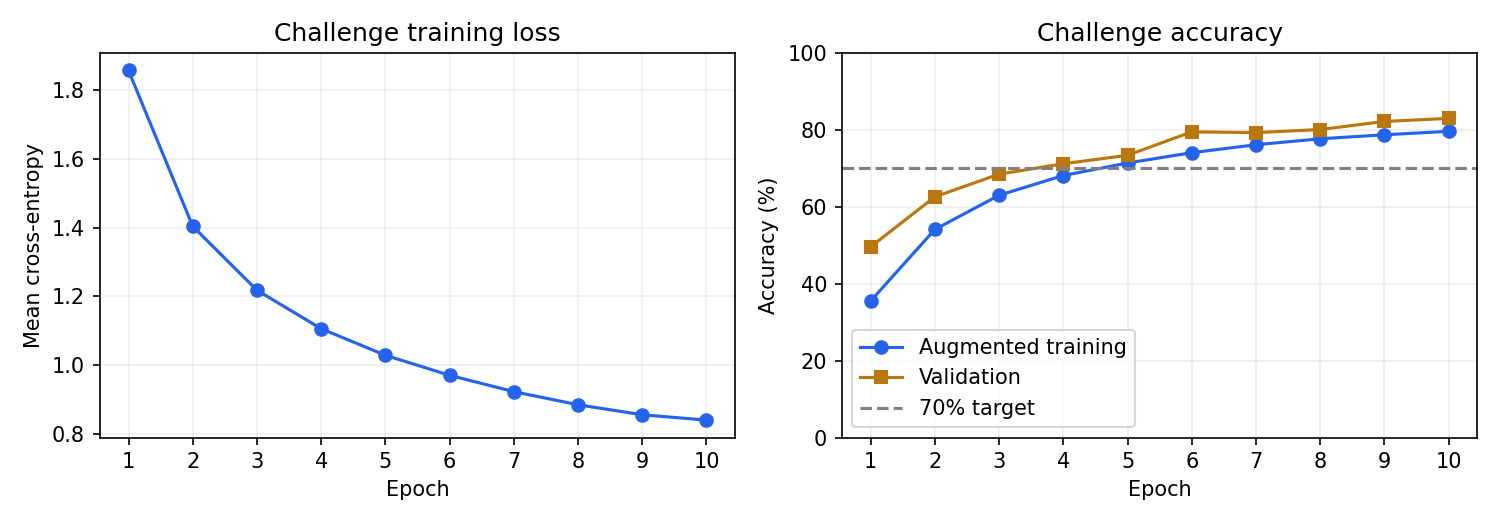

In [23]:
# Six 3x3 convolutions: [conv-BN-ReLU] x 2, then pool, at each width.
# All architecture/hyperparameter selection uses validation data only.
class CIFARChallengeNet(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_channels = 3
        for width in (24, 48, 96):
            for _ in range(2):
                layers.extend([
                    nn.Conv2d(in_channels, width, 3, padding=1, bias=False),
                    nn.BatchNorm2d(width),
                    nn.ReLU(inplace=True),
                ])
                in_channels = width
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(96 * 4 * 4, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(256, 10),
        )
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(layer.weight)
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x))

# Restart the seed so challenge results do not depend on baseline-cell reruns.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
augment = T.Compose([
    T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])
challenge_data = dset.CIFAR10(DATA_ROOT, train=True, download=False, transform=augment)
challenge_loader = DataLoader(
    challenge_data, batch_size=128,
    sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN)), num_workers=0,
)
model = CIFARChallengeNet().to(device)
optimizer = optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=5e-5)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
output_dir = Path('output/pytorch')
output_dir.mkdir(parents=True, exist_ok=True)
challenge_history = []
best_val_acc = -1.0
best_state = None

for epoch in range(1, 11):
    started = time.perf_counter()
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    learning_rate = optimizer.param_groups[0]['lr']
    for x, y in challenge_loader:
        x = x.to(device=device, dtype=dtype)
        y = y.to(device=device, dtype=torch.long)
        optimizer.zero_grad(set_to_none=True)
        scores = model(x)
        loss = criterion(scores, y)
        if not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite challenge loss')
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        correct += (scores.argmax(dim=1) == y).sum().item()
        count += y.size(0)
    val_acc = check_accuracy_part34(loader_val, model, quiet=True)
    row = {'epoch': epoch, 'learning_rate': learning_rate,
           'train_loss': loss_sum / count, 'train_acc': correct / count,
           'val_acc': val_acc, 'seconds': time.perf_counter() - started}
    challenge_history.append(row)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        best_state = {name: value.detach().cpu().clone()
                      for name, value in model.state_dict().items()}
        torch.save({'model_state_dict': best_state, 'epoch': epoch,
                    'val_acc': val_acc, 'seed': SEED,
                    'architecture': 'CIFARChallengeNet(24,48,96)'},
                   output_dir / 'best_model.pt')
    scheduler.step()
    (output_dir / 'challenge_history.json').write_text(json.dumps(challenge_history, indent=2))
    print('Epoch %2d/10 | loss %.4f | train %.2f%% | val %.2f%% | %.1fs' %
          (epoch, row['train_loss'], 100 * row['train_acc'], 100 * val_acc, row['seconds']), flush=True)

best_model = copy.deepcopy(model)
best_model.load_state_dict(best_state)
best_model.to(device).eval()
print('Best validation accuracy: %.2f%% at epoch %d' % (100 * best_val_acc, best_epoch))
assert best_val_acc >= 0.70, 'Continue validation-only tuning before evaluating the test set.'

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot([r['epoch'] for r in challenge_history], [r['train_loss'] for r in challenge_history], 'o-', color='#2563eb')
axes[0].set(xlabel='Epoch', ylabel='Mean cross-entropy', title='Challenge training loss')
axes[1].plot([r['epoch'] for r in challenge_history], [100*r['train_acc'] for r in challenge_history], 'o-', color='#2563eb', label='Augmented training')
axes[1].plot([r['epoch'] for r in challenge_history], [100*r['val_acc'] for r in challenge_history], 's-', color='#b9770e', label='Validation')
axes[1].axhline(70, linestyle='--', color='gray', label='70% target')
axes[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Challenge accuracy')
axes[1].legend()
for ax in axes:
    ax.set_xticks(range(1, 11))
    ax.grid(alpha=0.2)
axes[1].set_ylim(0, 100)
fig.tight_layout()
fig.savefig(output_dir / 'challenge_training.png', dpi=150)
plt.show()


## Describe what you did 

In the cell below you should write an explanation of what you did, any additional features that you implemented, and/or any graphs that you made in the process of training and evaluating your network.

I used a six-convolution network with three blocks. Each block has two 3x3 convolutions followed by batch normalization and ReLU, then 2x2 max pooling. The channel widths are 24, 48, and 96. The classifier has 256 ReLU units, dropout with probability 0.2, and ten output scores. Convolutional and linear weights use Kaiming normal initialization.

The challenge uses all 49,000 training images with random crops (four-pixel padding) and horizontal flips. Validation uses the remaining 1,000 original training images without augmentation. I trained for ten epochs using AdamW (initial learning rate 0.002, weight decay 0.0005), cosine learning-rate decay to 0.00005, batch size 128, and cross-entropy with label smoothing 0.05. The checkpoint is selected using validation accuracy only, including batch-normalization running statistics. The original test split is reserved for one final evaluation.

The executed cells below/above record the measured best validation accuracy and final test accuracy; the training curves and checkpoint are saved under `output/pytorch/`.

Measured results from the executed notebook:

| One-epoch baseline | Validation accuracy |
|---|---:|
| Barebones FC | 42.00% |
| Barebones CNN | 49.40% |
| Module FC | 42.40% |
| Module CNN | 49.40% |
| Sequential FC | 44.40% |
| Sequential CNN | 59.10% |

The challenge first exceeded the 70% target at epoch 4. Its best validation accuracy was **83.00% at epoch 10**. After fixing the architecture, hyperparameters, and selected checkpoint, I evaluated the test set once: **81.45% on 10,000 test images**. The validation/test difference is 1.55 percentage points; the validation set has only 1,000 images and was also used to select the checkpoint. Training accuracy in the plot is measured on augmented images with dropout active, whereas validation accuracy uses unaugmented images in evaluation mode. All six baselines were trained for one full epoch, and the challenge was trained for ten full epochs, using CPU execution with three PyTorch threads.


## Test set -- run this only once

Now that we've gotten a result we're happy with, we test our final model on the test set (which you should store in best_model). Think about how this compares to your validation set accuracy.

In [24]:
# Architecture and hyperparameters are now fixed. Evaluate the selected
# validation checkpoint on the original 10,000 test examples exactly once.
cifar10_test = dset.CIFAR10(DATA_ROOT, train=False, download=False, transform=transform)
loader_test = DataLoader(cifar10_test, batch_size=128, num_workers=0)
final_test_acc = check_accuracy_part34(loader_test, best_model)
final_results = {'seed': SEED, 'epochs': 10, 'best_epoch': best_epoch,
                 'best_val_acc': best_val_acc, 'test_acc': final_test_acc}
(output_dir / 'final_results.json').write_text(json.dumps(final_results, indent=2))
print('Saved results to', output_dir.resolve())


test: 8145 / 10000 correct (81.45%)
Saved results to /Users/while/Desktop/cs/682/assignment2/output/pytorch
